[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/22_rnns_lstms.ipynb)

# 22 · RNNs & LSTMs: Networks With Memory

**Part 3 — Deep learning** · Notebook 22 of 27

Images have a fixed size and a spatial structure; CNNs exploit both. Text, speech, sensor readings, stock prices, and DNA are different: they come as **sequences**, their length varies, and **order matters**. "The dog bit the man" and "the man bit the dog" contain the same words. A model for sequences needs to read one element at a time and carry forward what it has seen so far.

A **recurrent neural network** (RNN) does exactly that. It keeps a hidden **state**, a vector that summarizes the past, and updates it at every step with the same small network: weight sharing across **time**, the way a CNN shares weights across **space** (CX lecture 13: *"one computation cell is shared"*). This notebook builds an RNN from scratch, shows why plain RNNs forget (the vanishing-gradient problem again, now across time steps), and builds the **LSTM**, whose additive "conveyor belt" memory fixes it. We finish with a character-level language model that learns to write fake Shakespeare, the direct ancestor of the GPT we'll build in notebook 25.

**What you'll learn**

1. Sequences: why order and variable length need a new architecture
2. The simple RNN cell, from scratch, and unrolling through time
3. Backpropagation through time (BPTT)
4. Why RNNs forget: vanishing and exploding gradients across time
5. Gradient clipping
6. **LSTM**: the conveyor belt and its three gates, built from scratch
7. A long-memory test: RNN vs. LSTM vs. GRU
8. Forecasting a time series
9. A character-level language model on Shakespeare
10. RNN shapes: one-to-many, many-to-one, many-to-many, and where they went next

*Course map: CX 4240 lecture 13 (recurrent neural networks: sequence prediction, variable-length inputs, the shared computation cell, simple RNN cells, BPTT, many-to-one / one-to-many / many-to-many uses, vanishing and exploding gradients, gradient clipping, the LSTM conveyor belt and forget/input/output gates, LSTM vs. ResNet, GRU) and the course cheat sheet's RNN/LSTM formulas.*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
import torch, torch.nn as nn, torch.nn.functional as F
import time, os, urllib.request
torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch {torch.__version__} on {device}")
print("Ready ✓")

Setup complete ✓


PyTorch 2.14.1+cu130 on cpu
Ready ✓


---
## 1. Sequences

Three things make sequences different from the fixed-size inputs we've seen:

- **Variable length.** Reviews, sentences, and recordings all have different lengths. An MLP needs a fixed number of inputs.
- **Order matters.** A bag-of-words representation (notebook 14) loses it; "not good, bad" and "not bad, good" become identical.
- **Long-range dependencies.** The subject at the start of a long sentence determines the verb form at its end.

A sliding window (feed the last $k$ elements to an MLP) handles some of this, but it forgets everything older than $k$ steps and needs separate weights for each position in the window. The RNN's answer: read one element at a time and keep a running summary.

---
## 2. The simple RNN cell

At each time step $t$, the cell combines the current input $x_t$ with the previous state $h_{t-1}$:

$$h_t = \tanh\big(W_{xh}\,x_t + W_{hh}\,h_{t-1} + b_h\big), \qquad y_t = W_{hy}\,h_t + b_y.$$

The **same** weights $W_{xh}, W_{hh}, W_{hy}$ are used at every step. Drawn "rolled up", it's one cell with a loop; **unrolled** over a sequence of length $T$, it's a $T$-layer deep network whose layers all share weights. Let's write it in NumPy and check it against PyTorch's `nn.RNN`:

In [2]:
def rnn_forward(X, Wxh, Whh, bh, h0=None):
    """X: (T, d_in). Returns all hidden states H: (T, d_h)."""
    h = np.zeros(Whh.shape[0]) if h0 is None else h0; H = []
    for x_t in X:                                      # one step at a time, same weights every step
        h = np.tanh(Wxh @ x_t + Whh @ h + bh); H.append(h)
    return np.array(H)

torch.manual_seed(0)
rnn_t = nn.RNN(input_size=3, hidden_size=4, batch_first=True)
Wxh = rnn_t.weight_ih_l0.detach().numpy(); Whh = rnn_t.weight_hh_l0.detach().numpy()
bh = (rnn_t.bias_ih_l0 + rnn_t.bias_hh_l0).detach().numpy()     # PyTorch keeps two bias vectors; their sum is our b_h
X_seq = np.random.default_rng(0).normal(size=(6, 3))
ours = rnn_forward(X_seq, Wxh, Whh, bh)
theirs = rnn_t(torch.tensor(X_seq, dtype=torch.float32)[None])[0][0].detach().numpy()
print("hidden states over 6 steps (ours):\n", ours.round(4))
print(f"max difference from nn.RNN: {np.abs(ours - theirs).max():.1e}")
print(f"parameters: {sum(p.numel() for p in rnn_t.parameters())}, the same for a sequence of length 6 or 6,000")

hidden states over 6 steps (ours):
 [[-0.7344 -0.2837 -0.5555 -0.0625]
 [-0.3572 -0.2656 -0.7578 -0.1541]
 [ 0.3021 -0.7501 -0.2961 -0.1922]
 [-0.5762  0.2082 -0.7927 -0.2189]
 [ 0.1872  0.5641 -0.5162 -0.3699]
 [-0.6797  0.411  -0.5048 -0.0671]]
max difference from nn.RNN: 4.0e-08
parameters: 36, the same for a sequence of length 6 or 6,000


The parameter count doesn't depend on the sequence length: the network handles any length with the same weights.

### What the hidden state remembers

A first task: a stream of random digits 0–9, and at each step, output the **sum of the last three digits**. The answer depends on inputs the network saw up to two steps ago, so it must store them in its state. Train a small RNN and look at its predictions:

test RMSE: 0.10 (on sums ranging from 0 to 27)


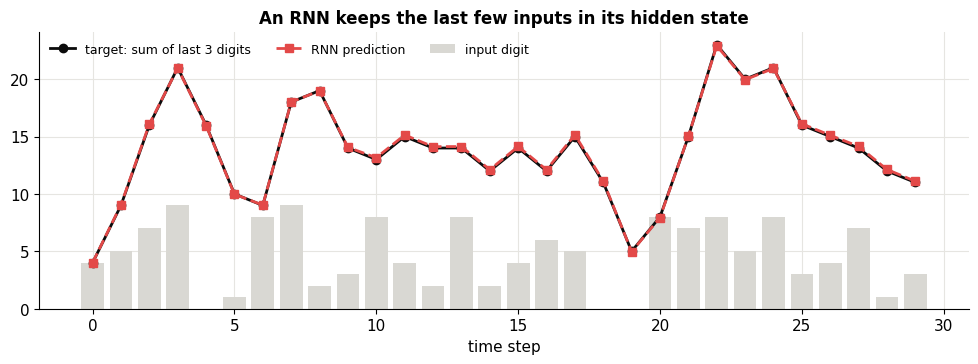

In [3]:
def make_sum3(n, T=30, seed=0):
    r = np.random.default_rng(seed); X = r.integers(0, 10, (n, T)).astype(np.float32)
    Y = X.copy(); Y[:, 1:] += X[:, :-1]; Y[:, 2:] += X[:, :-2]
    return torch.tensor(X[..., None] / 9), torch.tensor(Y[..., None] / 27)   # scale inputs and targets to [0, 1]

class SeqRegressor(nn.Module):
    def __init__(self, cell="rnn", hidden=32):
        super().__init__()
        self.rnn = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[cell](1, hidden, batch_first=True)
        self.out = nn.Linear(hidden, 1)
    def forward(self, x): return self.out(self.rnn(x)[0])           # a prediction at every step (many-to-many)

Xs3, Ys3 = make_sum3(2000); Xs3_te, Ys3_te = make_sum3(200, seed=1)
torch.manual_seed(0); m3 = SeqRegressor("rnn"); opt = torch.optim.Adam(m3.parameters(), lr=3e-3)
for step in range(1500):
    idx = torch.randint(0, len(Xs3), (64,)); loss = F.mse_loss(m3(Xs3[idx]), Ys3[idx])
    opt.zero_grad(); loss.backward(); opt.step()
with torch.no_grad(): pred = m3(Xs3_te)
rmse = ((pred - Ys3_te) ** 2).mean().sqrt().item() * 27
print(f"test RMSE: {rmse:.2f} (on sums ranging from 0 to 27)")
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.bar(range(30), Xs3_te[0, :, 0] * 9, color=C["light"], label="input digit")
ax.plot(range(30), Ys3_te[0, :, 0] * 27, "o-", color=C["ink"], label="target: sum of last 3 digits")
ax.plot(range(30), pred[0, :, 0] * 27, "s--", color=C["red"], label="RNN prediction")
ax.set(xlabel="time step", title="An RNN keeps the last few inputs in its hidden state"); ax.legend(ncol=3, fontsize=9); plt.show()

---
## 3. Backpropagation through time

Training an RNN means backpropagating through the **unrolled** network (CX lecture 13: *"backpropagation through unrolling steps"*). The loss is the sum of per-step losses, and since the same weights are used at every step, their gradient is the **sum over time steps** of the per-step contributions:

$$\frac{\partial\mathcal{L}}{\partial W_{hh}} = \sum_{t=1}^{T}\frac{\partial\mathcal{L}}{\partial h_t}\,\frac{\partial h_t}{\partial W_{hh}}\Big|_{\text{local}}, \qquad \frac{\partial\mathcal{L}}{\partial h_t} = \frac{\partial\mathcal{L}_t}{\partial h_t} + \frac{\partial\mathcal{L}}{\partial h_{t+1}}\,\frac{\partial h_{t+1}}{\partial h_t}.$$

The second equation is the backward recursion: the error at step $t$ includes the error flowing back from all future steps. Autograd does all of this for us (`loss.backward()` on the unrolled graph), but the recursion explains the RNN's central weakness.

---
## 4. Why RNNs forget

How much does the state at step $T$ depend on the state at an earlier step $t$? By the chain rule,

$$\frac{\partial h_T}{\partial h_t} = \prod_{k=t+1}^{T}\frac{\partial h_k}{\partial h_{k-1}} = \prod_{k=t+1}^{T}\mathrm{diag}\big(1 - h_k^2\big)\,W_{hh}.$$

A product of $T - t$ matrices. Roughly, each factor multiplies the gradient by the size of $W_{hh}$ (its largest singular value) times a tanh slope that is at most 1. If that's below 1, the product **shrinks exponentially** with the distance $T - t$: the gradient from a distant past vanishes, and the network can't learn long-range dependencies. If it's above 1, the product can **explode** (CX: *"backward flow of gradients in RNN can explode or vanish"*; the cheat sheet: $\|W_h\| < 1$ → vanishing, $> 1$ → exploding). 🎚️ **Scale the recurrent weights** and watch the gradient's reach:

In [4]:
def jacobian_norms(scale=1.0, T=60, d=32, seed=0):
    r = np.random.default_rng(seed)
    Q, _ = np.linalg.qr(r.normal(size=(d, d)))                     # orthogonal: all singular values 1
    Whh_ = scale * Q; Wxh_ = r.normal(0, 0.5, (d, 1))
    x = r.normal(size=(T, 1)); h = np.zeros(d); Hs = []
    for t in range(T): h = np.tanh(Wxh_ @ x[t] + Whh_ @ h); Hs.append(h)
    J = np.eye(d); norms = [1.0]
    for k in range(T - 1, 0, -1):                                  # ∂h_T/∂h_t, going back one step at a time
        J = J @ (np.diag(1 - Hs[k] ** 2) @ Whh_); norms.append(np.linalg.norm(J, 2))
    return np.array(norms)

def vanishing_demo(scale=0.9):
    fig, ax = plt.subplots(figsize=(10, 4))
    for s_, col in [(0.5, C["light"]), (1.0, C["light"]), (1.5, C["light"])]:
        ax.semilogy(jacobian_norms(s_), color=col, lw=1)
    n = jacobian_norms(scale); ax.semilogy(n, color=C["red"], lw=2.5, label=f"recurrent weights = {scale:.2f} × (orthogonal matrix)")
    ax.axhline(1, color=C["ink"], lw=0.8)
    ax.set(ylim=(1e-12, 1e8), xlabel="how many steps back, T − t", ylabel="‖∂h_T / ∂h_t‖ (log scale)",
           title=f"after 50 steps: {n[50]:.1e}   (grey: scale 0.5, 1.0, 1.5)"); ax.legend(loc="lower left")
    plt.show()

interact(vanishing_demo, scale=FloatSlider(value=0.9, min=0.3, max=2.0, step=0.05, description="scale"));

Below a scale of about 1, the sensitivity of the present to the past decays exponentially: 50 steps back it's essentially zero, so a training signal about something 50 steps ago never reaches the weights that would need to remember it. Above 1, the tanh saturation fights the growth (it caps the activations and shrinks its own slope), but the gradient can still blow up in bursts. The window of usable memory is narrow, and gradient descent can't easily keep the network inside it. That's the motivation for the LSTM.

---
## 5. Gradient clipping

Exploding gradients have a simple, crude fix (CX lecture 13): **clip** them. If the gradient's total norm exceeds a threshold $c$, rescale it to have norm $c$: $g \leftarrow g \cdot \min(1, c/\|g\|)$. The direction is kept; only the step size is capped, so one huge gradient can't throw the parameters far away. In PyTorch it's one line before `optimizer.step()`:

```python
torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
```

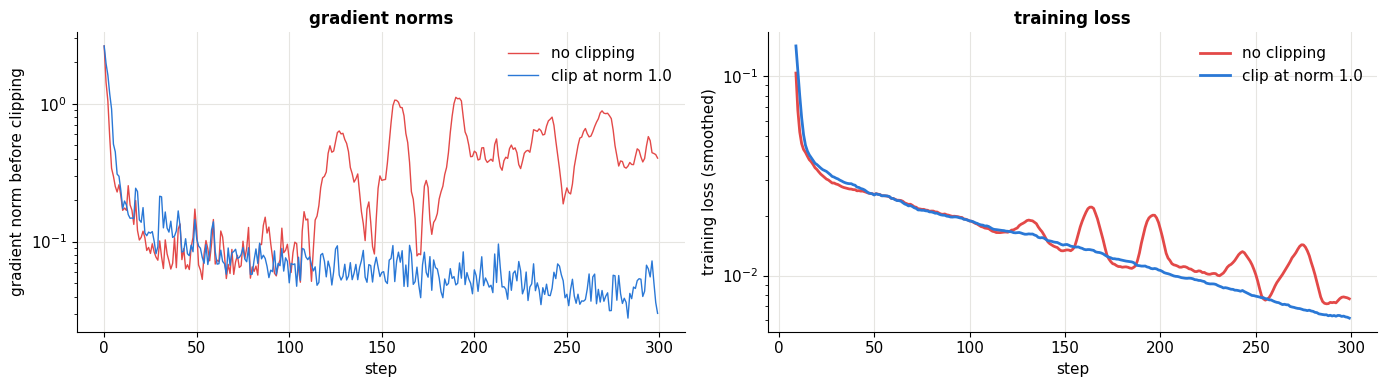

In [5]:
def train_with_clip(clip, steps=300, lr=0.05, seed=0):
    torch.manual_seed(seed); m = SeqRegressor("rnn", hidden=32)
    with torch.no_grad(): m.rnn.weight_hh_l0.mul_(2.5)              # start with large recurrent weights: an exploding regime
    opt = torch.optim.SGD(m.parameters(), lr=lr); losses, gnorms = [], []
    for step in range(steps):
        idx = torch.randint(0, len(Xs3), (64,)); loss = F.mse_loss(m(Xs3[idx]), Ys3[idx])
        opt.zero_grad(); loss.backward()
        gn = torch.nn.utils.clip_grad_norm_(m.parameters(), max_norm=clip if clip else 1e9)
        opt.step(); losses.append(loss.item()); gnorms.append(gn.item())
    return np.array(losses), np.array(gnorms)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for clip, col in [(None, C["red"]), (1.0, C["blue"])]:
    l_, g_ = train_with_clip(clip)
    lab = "no clipping" if clip is None else f"clip at norm {clip}"
    axes[0].semilogy(g_, color=col, lw=1, label=lab); axes[1].semilogy(pd.Series(l_).rolling(10).mean(), color=col, label=lab)
axes[0].set(xlabel="step", ylabel="gradient norm before clipping", title="gradient norms"); axes[0].legend()
axes[1].set(xlabel="step", ylabel="training loss (smoothed)", title="training loss"); axes[1].legend()
fig.tight_layout(); plt.show()

Starting from large recurrent weights, the raw gradient norms without clipping repeatedly jump up by an order of magnitude in the second half of training, and each jump shows up as a spike in the loss: the parameters get kicked away from where they were heading. With clipping, each step is bounded and the loss keeps falling smoothly. Clipping handles explosion; it does nothing for vanishing gradients (you can't scale up a gradient that carries no information).

---
## 6. LSTM: the conveyor belt

The **long short-term memory** cell (Hochreiter & Schmidhuber, 1997) adds a second state, the **cell state** $c_t$, which CX lecture 13 (following Chris Olah's famous diagrams) calls the **conveyor belt**: information flows along it from step to step with only small, deliberate changes. Three **gates**, each a sigmoid layer outputting numbers between 0 ("let nothing through") and 1 ("let everything through"), control it:

$$\begin{aligned}
f_t &= \sigma(W_f[h_{t-1}, x_t] + b_f) &&\text{forget gate: how much of the old memory to keep}\\
i_t &= \sigma(W_i[h_{t-1}, x_t] + b_i) &&\text{input gate: how much new information to write}\\
\tilde c_t &= \tanh(W_c[h_{t-1}, x_t] + b_c) &&\text{candidate new values}\\
c_t &= f_t \odot c_{t-1} + i_t \odot \tilde c_t &&\text{update the conveyor belt}\\
o_t &= \sigma(W_o[h_{t-1}, x_t] + b_o) &&\text{output gate: how much of the memory to reveal}\\
h_t &= o_t \odot \tanh(c_t) &&\text{new hidden state}
\end{aligned}$$

The key line is the cell update. It's **additive**: $c_t = f_t \odot c_{t-1} + (\text{new stuff})$. So $\partial c_t/\partial c_{t-1} = f_t$, elementwise, with no weight matrix and no squashing in between. When the forget gate is near 1, gradient flows back along the belt almost unchanged, over hundreds of steps. CX lecture 13 points out the parallel with ResNet (notebook 21): both fix vanishing gradients with an additive shortcut, $x + f(x)$ across layers, $c_{t-1} + \text{update}$ across time.

Let's implement one LSTM step in NumPy and check it against `nn.LSTM`:

In [6]:
def lstm_step(x, h, c, W, b):
    """W: (4·d_h, d_in + d_h) stacking the input, forget, candidate, output blocks in PyTorch's order (i, f, g, o)."""
    z = W @ np.concatenate([x, h]) + b; d = len(h)
    i, f, g, o = 1 / (1 + np.exp(-z[:d])), 1 / (1 + np.exp(-z[d:2 * d])), np.tanh(z[2 * d:3 * d]), 1 / (1 + np.exp(-z[3 * d:]))
    c_new = f * c + i * g                                   # the conveyor belt: additive update
    h_new = o * np.tanh(c_new)
    return h_new, c_new, dict(input=i, forget=f, output=o)

torch.manual_seed(0); lstm_t = nn.LSTM(3, 4, batch_first=True)
W = np.concatenate([lstm_t.weight_ih_l0.detach().numpy(), lstm_t.weight_hh_l0.detach().numpy()], axis=1)
b = (lstm_t.bias_ih_l0 + lstm_t.bias_hh_l0).detach().numpy()
h, c = np.zeros(4), np.zeros(4); Hs = []
for x_t in X_seq: h, c, _ = lstm_step(x_t, h, c, W, b); Hs.append(h)
theirs = lstm_t(torch.tensor(X_seq, dtype=torch.float32)[None])[0][0].detach().numpy()
print(f"max difference from nn.LSTM over 6 steps: {np.abs(np.array(Hs) - theirs).max():.1e}")
print(f"parameters: RNN {sum(p.numel() for p in rnn_t.parameters())}, LSTM {sum(p.numel() for p in lstm_t.parameters())} (4× : one block per gate + candidate)")

max difference from nn.LSTM over 6 steps: 3.0e-08
parameters: RNN 36, LSTM 144 (4× : one block per gate + candidate)


The **GRU** (gated recurrent unit; Cho et al., 2014) is a popular simplification: it merges the cell and hidden states and uses two gates (update and reset) instead of three. It has 3 weight blocks instead of 4 and often performs about as well.

---
## 7. A long-memory test

To see the difference, we need a task where the answer depends on something far in the past. The **recall task**: each input has two channels. Channel 1 is pure noise at every step. Channel 2 is zero everywhere except at the **first** step, where it holds +1 or −1. At the **last** step the network must output that sign. Everything in between is distraction.

We vary the sequence length and train a vanilla RNN and an LSTM of the same hidden size on each, with the same budget (1,000 steps of Adam, gradient clipping). For the LSTM we try two initializations: PyTorch's default (all biases near 0, so the forget gate starts at about $\sigma(0) = 0.5$, which halves the memory every step), and a **forget-gate bias of +3** (gate ≈ 0.95 at the start, "remember by default"), a standard trick (Gers et al., 2000; Jozefowicz et al., 2015). We report the test **cross-entropy**: $\ln 2 \approx 0.69$ means the network learned nothing; near 0 means it solved the task.

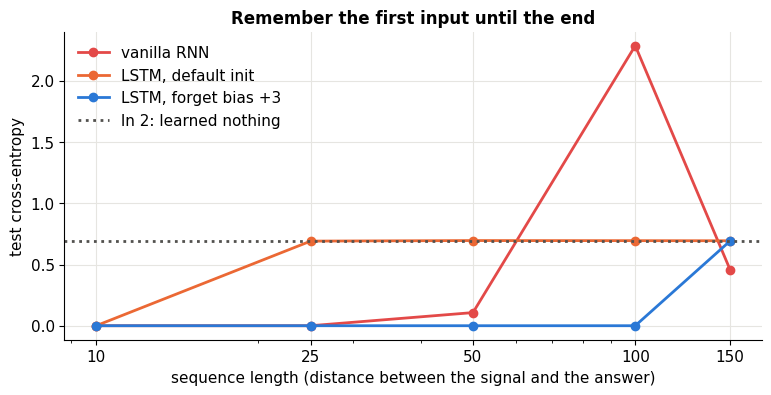

,vanilla RNN,"LSTM, default init","LSTM, forget bias +3"
length,,,
10,0.000,0.000,0.000
25,0.000,0.691,0.000
50,0.107,0.696,0.000
100,2.287,0.695,0.000
150,0.456,0.694,0.693


In [7]:
def make_recall(n, T, seed=0):
    r = np.random.default_rng(seed); X = np.zeros((n, T, 2), np.float32); X[:, :, 0] = r.normal(0, 1, (n, T))   # channel 1: noise
    sign = r.choice([-1.0, 1.0], n).astype(np.float32); X[:, 0, 1] = sign                                      # channel 2: the signal, step 0 only
    return torch.tensor(X), torch.tensor((sign > 0).astype(np.int64))

class SeqClassifier(nn.Module):
    def __init__(self, cell, hidden=32, forget_bias=None):
        super().__init__(); self.rnn = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[cell](2, hidden, batch_first=True); self.out = nn.Linear(hidden, 2)
        if forget_bias is not None:                                   # PyTorch orders the LSTM blocks (input, forget, cell, output)
            with torch.no_grad(): self.rnn.bias_ih_l0[hidden:2 * hidden].fill_(forget_bias)
    def forward(self, x): return self.out(self.rnn(x)[0][:, -1])     # read only the final state (many-to-one)

def train_recall(cell, T, forget_bias=None, steps=1000, hidden=32, seed=0):
    Xr, yr = make_recall(4000, T); torch.manual_seed(seed); m = SeqClassifier(cell, hidden, forget_bias); opt = torch.optim.Adam(m.parameters(), lr=5e-3)
    for step in range(steps):
        idx = torch.randint(0, len(Xr), (64,)); loss = F.cross_entropy(m(Xr[idx]), yr[idx])
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
    return m

recall = {}; lengths = [10, 25, 50, 100, 150]
configs = [("vanilla RNN", "RNN", None), ("LSTM, default init", "LSTM", None), ("LSTM, forget bias +3", "LSTM", 3.0)]
for name, cell, fb in configs:
    for T in lengths:
        m = train_recall(cell, T, fb); Xt, yt = make_recall(500, T, seed=1)
        with torch.no_grad(): recall[(name, T)] = F.cross_entropy(m(Xt), yt).item()
fig, ax = plt.subplots(figsize=(9, 4))
for (name, _, _), col in zip(configs, [C["red"], C["orange"], C["blue"]]):
    ax.plot(lengths, [recall[(name, T)] for T in lengths], "o-", color=col, lw=2, label=name)
ax.axhline(np.log(2), color=C["muted"], ls=":", label="ln 2: learned nothing"); ax.set(xscale="log", xticks=lengths, xticklabels=lengths,
       xlabel="sequence length (distance between the signal and the answer)", ylabel="test cross-entropy", title="Remember the first input until the end")
ax.legend(); plt.show()
pd.DataFrame({name: [recall[(name, T)] for T in lengths] for name, _, _ in configs}, index=pd.Index(lengths, name="length")).round(3)

For short sequences everything works. As the gap grows, the vanilla RNN's results become erratic: nearly solved at 50, partly at 150, and at 100 its loss is far *above* $\ln 2$ (it latched onto noise and is confidently wrong). Whether the faint gradient from the end reaches step 0 depends on luck in the training run. The LSTM with **default** initialization does worst of all: with forget gates starting near 0.5, the signal is halved at every step and the gradient back to step 0 is about $0.5^{T}$, so it never discovers the dependency. With the forget bias set to +3, the same LSTM starts out remembering, and it solves every length up to 100 within the budget. (At 150 it would need more training.) The architecture gives the LSTM the *ability* to carry information and gradients over long gaps; a sensible initialization lets training find it. The GRU behaves similarly to the LSTM and has its own gate initialization conventions.

### Watching the gates

What does the LSTM actually do? Train one on length-60 sequences, feed it two sequences that differ only in the sign at step 0, and plot the memory cell that ends up holding the most information, along with its forget gate:

test accuracy at length 60: 100.0%


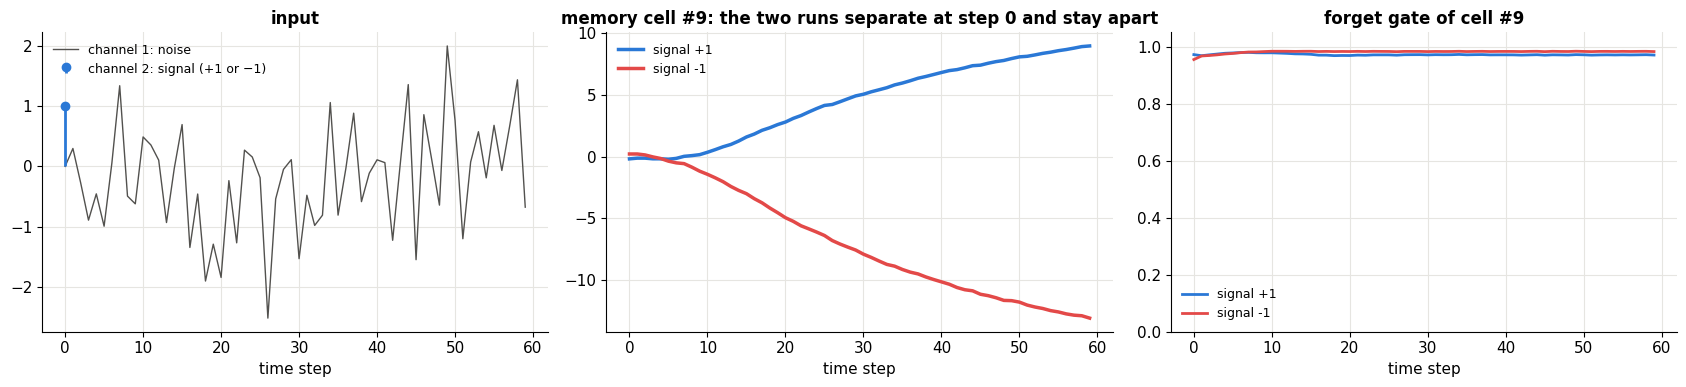

In [8]:
T_show = 60
lstm_m = train_recall("LSTM", T_show, forget_bias=3.0, hidden=16)
Xt, yt = make_recall(500, T_show, seed=1)
with torch.no_grad(): print(f"test accuracy at length {T_show}: {(lstm_m(Xt).argmax(1) == yt).float().mean():.1%}")
Wl = np.concatenate([lstm_m.rnn.weight_ih_l0.detach().numpy(), lstm_m.rnn.weight_hh_l0.detach().numpy()], 1)
bl = (lstm_m.rnn.bias_ih_l0 + lstm_m.rnn.bias_hh_l0).detach().numpy()
x_base = make_recall(1, T_show, seed=7)[0][0].numpy()
runs = {}
for sgn in (1, -1):
    x_ex = x_base.copy(); x_ex[0, 1] = sgn
    h, c = np.zeros(16), np.zeros(16); cs, fs = [], []
    for x_t in x_ex: h, c, g = lstm_step(x_t, h, c, Wl, bl); cs.append(c.copy()); fs.append(g["forget"].copy())
    runs[sgn] = (np.array(cs), np.array(fs))
k = np.argmax(np.abs(runs[1][0][-1] - runs[-1][0][-1]))              # the cell whose final value depends most on the sign
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].plot(x_base[:, 0], color=C["muted"], lw=1, label="channel 1: noise"); axes[0].stem([0], [1], linefmt=C["blue"], markerfmt="o", basefmt=" ", label="channel 2: signal (+1 or −1)")
axes[0].set(xlabel="time step", title="input"); axes[0].legend(fontsize=9)
for sgn, col in [(1, C["blue"]), (-1, C["red"])]:
    axes[1].plot(runs[sgn][0][:, k], color=col, lw=2.5, label=f"signal {sgn:+d}"); axes[2].plot(runs[sgn][1][:, k], color=col, lw=2, label=f"signal {sgn:+d}")
axes[1].set(xlabel="time step", title=f"memory cell #{k}: the two runs separate at step 0 and stay apart"); axes[1].legend(fontsize=9)
axes[2].set(xlabel="time step", ylim=(0, 1.05), title=f"forget gate of cell #{k}"); axes[2].legend(fontsize=9)
fig.tight_layout(); plt.show()

The two runs see identical noise; only the first step differs. The memory cell starts out almost identical in both runs, then the traces drift steadily apart, in opposite directions, for all 60 steps: the small difference planted at step 0 is fed back through the hidden state, and at every step the cell **adds** a little more in the direction of the sign. Its forget gate stays near 0.98 the whole time, so nothing is lost along the way. At the end, the output layer reads the sign off the cell's large positive or negative value. Nobody programmed this; the LSTM learned to use a cell as an accumulator of evidence, exactly what the additive conveyor belt makes easy.

---
## 8. Forecasting a time series

RNNs are a natural fit for forecasting: read the history, predict the next value. A synthetic series with two seasonal cycles, a trend, and noise (think of hourly electricity demand):

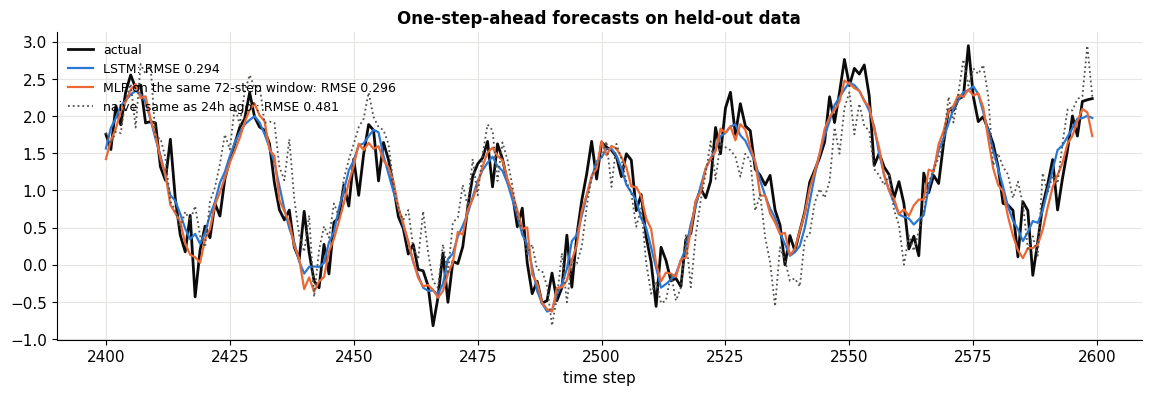

In [9]:
r_ = np.random.default_rng(3); n_t = 3000; t_ = np.arange(n_t)
series = (np.sin(2 * np.pi * t_ / 24) + 0.5 * np.sin(2 * np.pi * t_ / (24 * 7)) + 0.0004 * t_ + 0.25 * r_.normal(size=n_t)).astype(np.float32)
win = 72
def windows(s, start, end):
    X = np.stack([s[i:i + win] for i in range(start, end - win)]); y = s[start + win:end]
    return torch.tensor(X[..., None]), torch.tensor(y[:, None])
split = 2400
s_mean, s_std = series[:split].mean(), series[:split].std(); s_norm = (series - s_mean) / s_std
Xw, yw = windows(s_norm, 0, split); Xw_te, yw_te = windows(s_norm, split - win, n_t)

class Forecaster(nn.Module):
    def __init__(self, cell="lstm", hidden=32):
        super().__init__(); self.rnn = {"lstm": nn.LSTM, "rnn": nn.RNN}[cell](1, hidden, batch_first=True); self.out = nn.Linear(hidden, 1)
    def forward(self, x): return self.out(self.rnn(x)[0][:, -1])
fc_models = {}
for name, model in [("LSTM", Forecaster("lstm")), ("MLP on the same 72-step window", nn.Sequential(nn.Flatten(), nn.Linear(win, 64), nn.ReLU(), nn.Linear(64, 1)))]:
    torch.manual_seed(0); opt = torch.optim.Adam(model.parameters(), lr=3e-3)
    for step in range(1200):
        idx = torch.randint(0, len(Xw), (64,)); loss = F.mse_loss(model(Xw[idx]), yw[idx]); opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad(): fc_models[name] = model(Xw_te).numpy().ravel() * s_std + s_mean
truth = yw_te.numpy().ravel() * s_std + s_mean
naive = series[split - 24:n_t - 24]                                   # "same as 24 hours ago"
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(t_[split:split + 200], truth[:200], color=C["ink"], lw=2, label="actual")
for (name, p), col in zip(fc_models.items(), [C["blue"], C["orange"]]):
    ax.plot(t_[split:split + 200], p[:200], color=col, lw=1.6, label=f"{name}: RMSE {np.sqrt(np.mean((p - truth) ** 2)):.3f}")
ax.plot(t_[split:split + 200], naive[:200], color=C["muted"], ls=":", lw=1.3, label=f"naive 'same as 24h ago': RMSE {np.sqrt(np.mean((naive - truth) ** 2)):.3f}")
ax.set(xlabel="time step", title="One-step-ahead forecasts on held-out data"); ax.legend(fontsize=9, loc="upper left"); plt.show()

Both neural forecasters beat the seasonal-naive baseline, and here the MLP on a fixed window does about as well as the LSTM: a 72-step window already contains everything this series needs (its main cycle is 24 steps). RNNs earn their keep when relevant history is long or of variable length. In practice, classical methods (exponential smoothing, ARIMA) and gradient-boosted trees on lag features remain strong baselines for forecasting, and should always be tried first.

---
## 9. A character-level language model

The most famous RNN demo (Karpathy, *The Unreasonable Effectiveness of Recurrent Neural Networks*, 2015): train an LSTM to predict the **next character** of a text, then let it write. The text is "tiny Shakespeare" (about 1.1 MB of Shakespeare's plays, public domain), downloaded from Karpathy's char-rnn repository. Each character becomes an integer, the network reads characters one at a time through an **embedding** layer (a learned vector per character), and a softmax over the vocabulary predicts the next one. This is many-to-many: a prediction at every step, trained with cross-entropy, exactly the training objective of GPT (notebook 25).

In [10]:
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
os.makedirs("data", exist_ok=True); path = "data/tinyshakespeare.txt"
if not os.path.exists(path): urllib.request.urlretrieve(url, path)
text = open(path, encoding="utf-8").read()
chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}; itos = {i: c for c, i in stoi.items()}
data = torch.tensor([stoi[c] for c in text], dtype=torch.long)
print(f"{len(text):,} characters, vocabulary of {len(chars)}: {''.join(chars)!r}")
print("-" * 60); print(text[:300])

1,115,394 characters, vocabulary of 65: "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
------------------------------------------------------------
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


In [11]:
class CharLSTM(nn.Module):
    def __init__(self, vocab, emb=64, hidden=256, layers=2):
        super().__init__()
        self.emb = nn.Embedding(vocab, emb); self.lstm = nn.LSTM(emb, hidden, num_layers=layers, batch_first=True, dropout=0.1); self.out = nn.Linear(hidden, vocab)
    def forward(self, idx, state=None):
        h, state = self.lstm(self.emb(idx), state); return self.out(h), state

n_split = int(0.9 * len(data)); train_data, val_data = data[:n_split], data[n_split:]
SEQ, BATCH = 100, 64
def get_batch(src):
    ix = torch.randint(0, len(src) - SEQ - 1, (BATCH,))
    x = torch.stack([src[i:i + SEQ] for i in ix]); y = torch.stack([src[i + 1:i + SEQ + 1] for i in ix])   # target = input shifted by one
    return x.to(device), y.to(device)

@torch.no_grad()
def sample(model, prompt="ROMEO:\n", n=400, temperature=1.0, seed=0):
    g = torch.Generator().manual_seed(seed); model.eval()
    idx = torch.tensor([[stoi[c] for c in prompt]], device=device); logits, state = model(idx); out = list(prompt)
    for _ in range(n):
        probs = F.softmax(logits[0, -1] / temperature, dim=0).cpu()
        nxt = torch.multinomial(probs, 1, generator=g).item(); out.append(itos[nxt])
        logits, state = model(torch.tensor([[nxt]], device=device), state)
    model.train(); return "".join(out)

STEPS = 1500                                          # ~10 minutes on a CPU; on a GPU try 5000+
torch.manual_seed(0); lm = CharLSTM(len(chars)).to(device); opt = torch.optim.Adam(lm.parameters(), lr=3e-3)
print(f"{sum(p.numel() for p in lm.parameters()):,} parameters; loss at init {np.log(len(chars)):.2f} = log(vocab size) expected")
snapshots, curve, t0 = {}, [], time.time()
for step in range(STEPS + 1):
    x, y = get_batch(train_data); logits, _ = lm(x)
    loss = F.cross_entropy(logits.reshape(-1, len(chars)), y.reshape(-1))
    opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(lm.parameters(), 1.0); opt.step()
    if step % 100 == 0:
        with torch.no_grad():
            xv, yv = get_batch(val_data); vl = F.cross_entropy(lm(xv)[0].reshape(-1, len(chars)), yv.reshape(-1)).item()
        curve.append((step, loss.item(), vl))
    if step in (0, 100, 300, STEPS): snapshots[step] = sample(lm, n=250, temperature=0.8)
print(f"trained {STEPS} steps in {time.time() - t0:.0f}s; final validation loss {curve[-1][2]:.2f} nats/char")

876,929 parameters; loss at init 4.17 = log(vocab size) expected


trained 1500 steps in 346s; final validation loss 1.52 nats/char


========== after 0 steps ==========
ROMEO:
t3ZrjmhPkqkARxLsXltUWHoHcu -exhjyU&aNdkIgAlsvSBUMycoRD$BygX-fntw
kVrM h&?j DJRbsOEHelC!BTg3xUhPRCs3Ma-'3KyporWiXkMvRJIRc:sZO;qJU,H:r?nK- mj$fxts!AHMLpwPjJRDf.HR'f IiVe$EoLg,Ak!DSc j'
sCuzyW3u!SB..SSqHImVe3xfSp-P$
-Oi$HATW-eQnNHssKNfMiIsPojqqdgfOIomOw

========== after 100 steps ==========
ROMEO:
Thy for this whonlend ouch mears! wo dishels fage come wight now here hath thigh of listeges him
We at of pordied we all sendart, trence my fatter we why to daim whis hithen the connts uzencut no. So pool the this mily my hond shat that of level of w

========== after 300 steps ==========
ROMEO:
Thy farise have not it Han mean
And before strengncoman you for mean? here to be compossed,
She the person or was we all send
And trune; my father we would for my life.

LEONTES:
I nos up the crount and to fail in mink.
Would the maring of light of w

========== after 1500 steps ==========
ROMEO:
Thou must know the firder of a king,
The treeches come of his tim

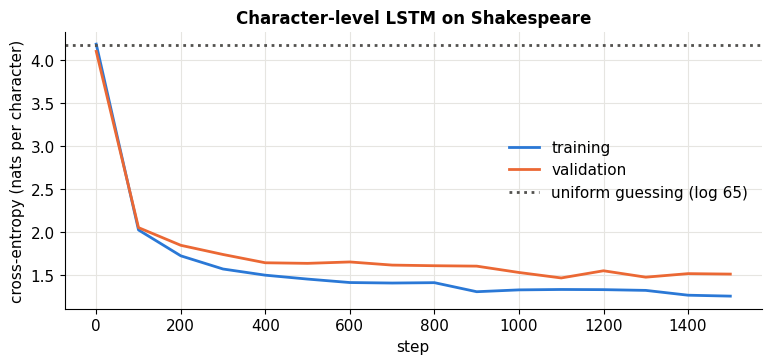

In [12]:
for step, s in snapshots.items():
    print(f"========== after {step} steps ==========\n{s}\n")
cv = np.array(curve)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(cv[:, 0], cv[:, 1], label="training"); ax.plot(cv[:, 0], cv[:, 2], label="validation")
ax.axhline(np.log(len(chars)), color=C["muted"], ls=":", label="uniform guessing (log 65)")
ax.set(xlabel="step", ylabel="cross-entropy (nats per character)", title="Character-level LSTM on Shakespeare"); ax.legend(); plt.show()

Watch it learn in stages. At step 0 it emits random characters. After just 100 steps it has learned spaces, common letter combinations, and many short real words ("for", "this", "come", "now"), strung into nonsense. By 300 steps, capitalized speaker names followed by colons and line breaks appear. By the end it writes pseudo-Shakespeare: invented but plausible words, character names, verse-like line lengths, and dialogue formatting, all learned from predicting one character at a time. It has no idea what any of it means, and the sentences don't hold together over more than a few words: the state is a small vector being asked to remember everything.

### Temperature

Sampling divides the logits by a **temperature** $\tau$ before the softmax. $\tau < 1$ sharpens the distribution (safer, more repetitive text), $\tau > 1$ flattens it (more creative, more errors). The same knob exists in every LLM API. 🎚️ **Try it:**

In [13]:
def temp_demo(temperature=0.8, seed=0):
    print(sample(lm, prompt="KING:\n", n=300, temperature=temperature, seed=seed))

interact(temp_demo, temperature=FloatSlider(value=0.8, min=0.2, max=2.0, step=0.1, description="τ"), seed=IntSlider(value=0, min=0, max=5, description="seed"));

---
## 10. RNN shapes, and where they went next

CX lecture 13's catalog of input/output shapes, all built from the same recurrent cell:

| Shape | Input → output | Example |
|---|---|---|
| one-to-one | vector → vector | ordinary classification (no recurrence needed) |
| **one-to-many** | vector → sequence | image captioning: a CNN encodes the image, an RNN writes the caption |
| **many-to-one** | sequence → vector | sentiment of a review; our recall task |
| **many-to-many** (aligned) | sequence → sequence of the same length | tagging each word; our char model and sum-of-3 task |
| **many-to-many** (encoder–decoder) | sequence → sequence of a different length | translation: an encoder RNN reads the sentence, a decoder RNN writes the translation |

Other practical variants: **bidirectional** RNNs (one reading forward, one backward, for tasks where the whole sequence is available) and **stacked** RNNs (several layers, as in our `CharLSTM`).

Encoder–decoder RNNs had a bottleneck: the whole input sentence had to be squeezed into the encoder's final state. In 2014, Bahdanau et al. let the decoder **look back at all the encoder's states** and choose which to focus on at each step. That mechanism, **attention**, turned out to be so effective that in 2017 Vaswani et al. dropped the recurrence entirely: *Attention Is All You Need*. Transformers process all positions in parallel (no step-by-step loop, so much faster on GPUs) and connect any two positions directly (no vanishing gradient across time). They replaced RNNs in language modeling, and notebook 25 builds one. RNN-like ideas are making a comeback, though, in "state-space models" that combine recurrent efficiency with transformer-like training.

---
## 11. Summary

- An **RNN** reads a sequence one element at a time, updating a hidden state $h_t = \tanh(W_{xh}x_t + W_{hh}h_{t-1} + b)$ with the **same weights** at every step, so it handles any length.
- It's trained by **backpropagation through time**: autograd on the unrolled network, with gradients summed over steps.
- The gradient from step $T$ to step $t$ is a product of $T - t$ Jacobians, so it **vanishes** or **explodes** exponentially. Explosion: **clip** the gradient norm. Vanishing: change the architecture.
- The **LSTM** adds a cell state updated **additively** ($c_t = f_t \odot c_{t-1} + i_t \odot \tilde c_t$) under the control of forget, input, and output gates, so information and gradients can flow across hundreds of steps (the same idea as ResNet's shortcut). The **GRU** is a lighter variant.
- A **character-level language model** trained to predict the next character learns spelling, formatting, and style. Scale that idea up and swap the RNN for a transformer, and you get GPT.

### ✏️ Exercises

1. Implement backpropagation through time by hand for the simple RNN (NumPy) on the sum-of-3 task, and check your gradients against PyTorch autograd.
2. Show that for the LSTM, $\partial c_t/\partial c_{t-1} = \mathrm{diag}(f_t)$ when the gates are treated as constants. Section 7 used a forget-gate bias of +3. Retrain the length-100 recall task with biases 0, 1, 2, 3, 5 and plot test loss against the bias. Why can too large a bias also hurt?
3. Extend the recall task to lengths 160 and 320. Where does the LSTM start failing with this training budget? Does more training or a GRU help?
4. Train the forecasting models on a series whose relevant history is longer than the window (for example, a 200-step cycle with a 72-step window). Which model degrades more?
5. Train the character model with a vanilla RNN (`nn.RNN`) instead of an LSTM, same budget. Compare validation loss and samples.
6. Build a many-to-one sentiment classifier on a small labeled text dataset of your choice (for example, reviews you write yourself, or the IMDB dataset if you have internet), using `nn.Embedding` + `nn.LSTM` + a linear layer on the final state.

### References

- CX 4240 lecture 13 (Recurrent Neural Networks) and the course cheat sheet.
- J. Elman, *Finding Structure in Time*, Cognitive Science (1990).
- S. Hochreiter & J. Schmidhuber, *Long Short-Term Memory*, Neural Computation (1997); F. Gers, J. Schmidhuber & F. Cummins, *Learning to Forget* (2000).
- Y. Bengio, P. Simard & P. Frasconi, *Learning Long-Term Dependencies with Gradient Descent is Difficult*, IEEE Trans. Neural Networks (1994); R. Pascanu, T. Mikolov & Y. Bengio, *On the difficulty of training recurrent neural networks*, ICML (2013) (gradient clipping).
- K. Cho et al., *Learning Phrase Representations using RNN Encoder–Decoder for Statistical Machine Translation* (2014) (GRU); D. Bahdanau, K. Cho & Y. Bengio, *Neural Machine Translation by Jointly Learning to Align and Translate* (2014) (attention).
- C. Olah, *Understanding LSTM Networks* (blog, 2015); A. Karpathy, *The Unreasonable Effectiveness of Recurrent Neural Networks* (blog, 2015) and the char-rnn repository (tiny Shakespeare).

**Next → [23 · Variational Autoencoders](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/23_vae.ipynb)**